# 01. PyTorch Workflow — Annotated Cheatsheet

This notebook fits a simple linear regression model using the same steps used
to train a neural network. Run cells from top to bottom; later sections reuse
the plotting function and variable names. A CPU is sufficient.

1. Prepare data and a train/test split.
2. Define a model and inspect its parameters.
3. Choose a loss and optimizer; run the training loop.
4. Evaluate predictions and inspect the fitted parameters.
5. Save and reload the model's state.
6. Repeat using `nn.Linear` on an available device (CUDA, MPS, or CPU).

**Original resource:** [PyTorch workflow notebook](https://github.com/mrdbourke/pytorch-deep-learning/blob/main/01_pytorch_workflow.ipynb).
**Packages:** PyTorch, Matplotlib, and scikit-learn (for the random-split example).
The save cells create small `.pth` files in a `models/` folder under the working directory.


In [30]:
import torch
from torch import nn             # Model layers, trainable parameters, and loss functions.
import matplotlib.pyplot as plt  # Data, predictions, and loss curves.

print("PyTorch version:", torch.__version__)


PyTorch version: 2.7.0


### 1. Prepare data

We simulate 50 observations from

$$y_i = b + w x_i + \epsilon_i,\qquad
  w=0.7,\quad b=0.3,\quad \epsilon_i\sim N(0,0.05^2).$$

We know the generating parameters, but the model sees only `X` and `y`.
Both have shape **`(50, 1)`**: observations in rows, one feature or response in columns.
The model will estimate a slope and intercept by minimizing a loss with gradient descent.


In [31]:
# True data-generating parameters; these are not the model's initial parameters.
weight = 0.7
bias = 0.3

# Seed once before simulation to repeat this noise sample.
torch.manual_seed(42)
start, end, step = 0, 1, 0.02

# arange() excludes end: 0.00, 0.02, ..., 0.98 gives 50 observations.
# unsqueeze(1) changes (50,) -> (50, 1), keeping an explicit feature axis.
X = torch.arange(start, end, step).unsqueeze(dim=1)
error = 0.05 * torch.randn(size=(len(X), 1))  # Noise SD = 0.05, shape (50, 1).
y = bias + weight * X + error                # Response shape (50, 1).

# Matching y and prediction shapes avoids unintended broadcasting in the loss.
X[:10], y[:10]


(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3963],
         [0.3884],
         [0.3730],
         [0.2367],
         [0.3899],
         [0.3083],
         [0.3818],
         [0.3178],
         [0.3744],
         [0.5084]]))

### Split data into training and testing sets

Training observations determine the model parameters. Held-out observations
show how predictions behave on data not used in gradient updates.


**Option A: random split.** For independent observations, `train_test_split`
can shuffle matched feature/response pairs into two sets. This example uses
separate names so it will not be confused with the ordered split used below.
For grouped or time-dependent data, the split should respect that structure.


In [32]:
from sklearn.model_selection import train_test_split

# The return order is X_train, X_test, y_train, y_test.
# X and y are split together so each response stays paired with its feature.
X_train_random, X_test_random, y_train_random, y_test_random = train_test_split(
    X, y,
    test_size=0.2,    # 20% (10 observations) held out; 80% (40) for training.
    shuffle=True,    # Shuffle row indices before splitting.
    random_state=42, # Repeats this split; separate from torch.manual_seed().
)
print("Random split sizes:", len(X_train_random), len(X_test_random))


Random split sizes: 40 10


**Option B: ordered split, used for the rest of this notebook.** The first 40
observations train the model; the last 10 are held out. Since `X` is increasing,
training inputs range from 0.00 to 0.78 and test inputs from 0.80 to 0.98.
This tests extrapolation beyond the training range, unlike the random split.


In [33]:
train_split = int(0.8 * len(X))  # Row index 40 separates the two sets.
X_train, y_train = X[:train_split], y[:train_split]  # Each shape (40, 1).
X_test, y_test = X[train_split:], y[train_split:]    # Each shape (10, 1).

# The slices preserve the feature/response axis of length 1.
print("Training shapes:", X_train.shape, y_train.shape)
print("Test shapes:", X_test.shape, y_test.shape)


Training shapes: torch.Size([40, 1]) torch.Size([40, 1])
Test shapes: torch.Size([10, 1]) torch.Size([10, 1])


#### Visualize data

In [34]:
def plot_predictions(train_data, train_labels, test_data, test_labels,
                     predictions=None):
    """Plot observed data and optional predictions at the test inputs.

    Inputs are one-feature/one-response tensors, typically shaped (n, 1).
    CPU, CUDA, and MPS tensors are accepted and converted for Matplotlib.
    """
    def as_numpy(tensor):
        # Detach from autograd, move to CPU, then flatten to a 1D array for plotting.
        return tensor.detach().cpu().numpy().reshape(-1)

    plt.figure(figsize=(8, 5))
    plt.scatter(as_numpy(train_data), as_numpy(train_labels),
                c="tab:blue", s=25, label="Training data")
    plt.scatter(as_numpy(test_data), as_numpy(test_labels),
                c="tab:green", s=25, label="Test data")

    # None means predictions have not been supplied; zero-valued predictions are valid.
    if predictions is not None:
        plt.scatter(as_numpy(test_data), as_numpy(predictions),
                    c="tab:red", marker="x", s=35, label="Predictions")

    plt.xlabel("Input x")
    plt.ylabel("Response y")
    plt.legend()
    plt.tight_layout()
    plt.show()


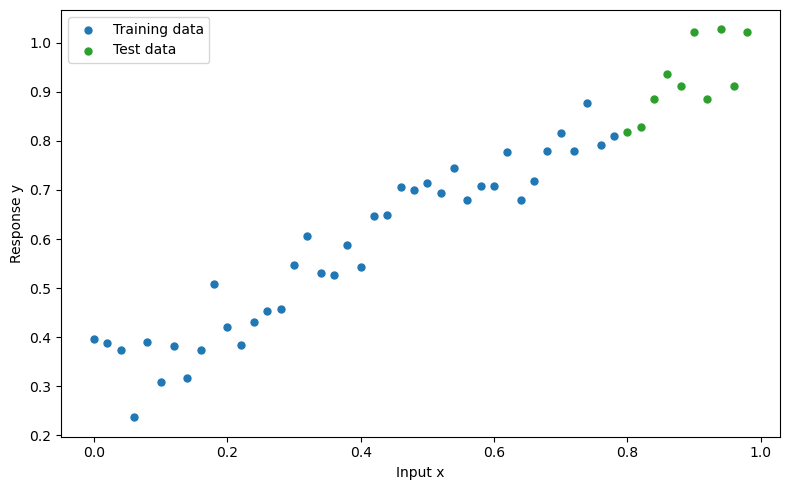

In [35]:
# Inspect the split before fitting: blue points train the model; green points are held out.
plot_predictions(train_data=X_train,
                 train_labels=y_train,
                 test_data=X_test,
                 test_labels=y_test)

### 2. Build a model

A custom PyTorch model subclasses `nn.Module`. Define its components in
`__init__()` and its input-to-output computation in `forward()`.
Here, the computation is simply $\widehat y = wx+b$.

`nn.Parameter` registers an attribute as a model parameter and enables gradient
tracking by default. An ordinary tensor attribute is not automatically registered
as a parameter. Call **`model(X)`**; PyTorch handles the call to `forward()`.


In [36]:
class LinearRegressionModel(nn.Module):
    def __init__(self):
        super().__init__()  # Initialize Module before assigning parameters or submodules.

        # Each parameter contains one float. Start from random values, not the truth.
        # nn.Parameter defaults to requires_grad=True; no extra flag is needed here.
        self.weights = nn.Parameter(torch.randn(1, dtype=torch.float32))
        self.bias = nn.Parameter(torch.randn(1, dtype=torch.float32))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Type hints document the input/output; they do not convert or validate x.
        # For x of shape (n, 1), the slope and intercept broadcast across all rows.
        # This method computes predictions only; it does not update the parameters.
        return self.weights * x + self.bias  # Output shape (n, 1).


### Model-building essentials

| Object / method | Role |
|---|---|
| `nn.Module` | Base class that tracks registered parameters, buffers, and child modules |
| `nn.Parameter` | A registered model parameter when assigned as a module attribute |
| `forward(x)` | Defines how inputs become predictions |
| `model.parameters()` | Iterates over parameter tensors; pass this to the optimizer |
| `model.state_dict()` | Maps names to parameter and persistent-buffer values for saving |
| `torch.optim` | Optimizers that update parameters using computed gradients |

Three separate actions: **forward** computes predictions, **backward** computes
derivatives, and **optimizer.step** updates parameters.


#### Check the contents of our PyTorch model

In [37]:
torch.manual_seed(42)  # Repeat the initial weights when rerunning this experiment.
model_0 = LinearRegressionModel()

# These are the actual parameter objects the optimizer will update.
list(model_0.parameters())


[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [38]:
# Names help identify what is stored. This simple model has weights and bias only.
# Larger models can also have persistent buffers, such as BatchNorm running statistics.
model_0.state_dict()


OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

### Predictions before training

Use `model.eval()` to select evaluation behavior and `torch.inference_mode()`
to skip gradient recording during prediction. These do different jobs:
`eval()` affects layers such as Dropout and BatchNorm; it does not disable autograd.
For this simple linear model, train/eval modes compute the same formula.


In [39]:
model_0.eval()  # Select evaluation behavior (a useful habit for all models).
with torch.inference_mode():
    # Predictions use the current RANDOM parameters, so a poor fit is expected.
    y_preds = model_0(X_test)  # Input (10, 1) -> output (10, 1).

y_preds


tensor([[0.3982],
        [0.4049],
        [0.4116],
        [0.4184],
        [0.4251],
        [0.4318],
        [0.4386],
        [0.4453],
        [0.4520],
        [0.4588]])

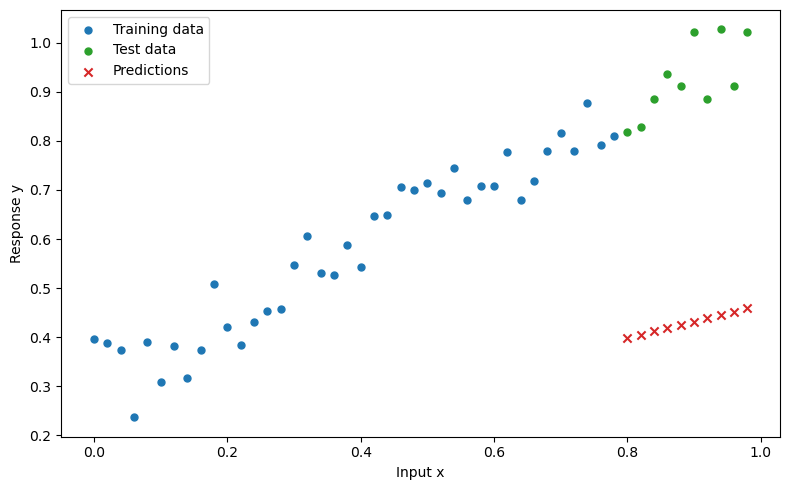

In [40]:
# Compare initial predictions with observed test responses before any parameter updates.
plot_predictions(train_data=X_train,
                 train_labels=y_train,
                 test_data=X_test,
                 test_labels=y_test, 
                 predictions=y_preds)

### 3. Train the model

#### Choose a loss and optimizer

We retain **mean absolute error (MAE)** from the original example:

$$L(w,b)=\frac{1}{n_{\rm train}}\sum_i
  |wx_i+b-y_i|.$$

`nn.L1Loss()` averages absolute errors; it does **not** add an L1 penalty on the
model weights. For ordinary least squares, use `nn.MSELoss()` instead.
A loss is the scalar objective; the optimizer uses its gradients to change the parameters.

[Loss functions](https://docs.pytorch.org/docs/stable/nn.html#loss-functions)
· [Optimizers](https://docs.pytorch.org/docs/stable/optim.html)


In [41]:
loss_fn = nn.L1Loss()  # reduction="mean" by default: average over all response entries.

# SGD receives references to model_0's parameters; no data are passed here.
# With no momentum, each update is theta <- theta - lr * gradient.
# lr is a multiplier for the gradient, not a fixed change in each parameter.
optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.01)


#### Training and evaluation loop

Each epoch here uses **all 40 training observations in one batch**, so one epoch
contains one optimizer step. With mini-batches, an epoch normally contains many steps.

| Step | Code | What changes? |
|---|---|---|
| Select training behavior | `model.train()` | Module mode flags |
| Forward pass | `pred = model(X_train)` | Builds predictions and the computation graph |
| Compute objective | `loss = loss_fn(pred, y_train)` | Produces a scalar loss |
| Clear old gradients | `optimizer.zero_grad()` | Resets parameter gradients |
| Differentiate | `loss.backward()` | Fills parameter `.grad` values |
| Update parameters | `optimizer.step()` | Changes weights and bias |

**Evaluation:** switch to `eval()`, enter `inference_mode()`, then compute predictions
and loss on held-out data. Do not call `backward()` or `step()` there.

**About the test curve:** this teaching example displays held-out loss during training.
If you use that curve to choose epochs, hyperparameters, or a model, those observations
serve as a **validation** set. Keep a separate test set for final performance reporting.


In [42]:
# Full-batch training: one pass over the training data and one update per epoch.
epochs = 500
train_loss_values, test_loss_values, epoch_count = [], [], []

for epoch in range(epochs):
    # 0. Select training behavior. This alone does not calculate gradients.
    model_0.train()

    # 1. Predict with current parameters: (40, 1) -> (40, 1).
    y_pred = model_0(X_train)

    # 2. Compute a scalar MAE. Predictions and targets must have matching shapes.
    loss = loss_fn(y_pred, y_train)

    # 3. Clear gradients from the previous step; backward() otherwise accumulates them.
    optimizer.zero_grad()

    # 4. Compute d(loss)/d(parameter) and store it in each parameter's .grad.
    loss.backward()

    # 5. Update this model's parameters using the gradients and learning rate.
    optimizer.step()

    # Evaluate THIS model after the update, without building a gradient graph.
    model_0.eval()
    with torch.inference_mode():
        test_pred = model_0(X_test)
        test_loss = loss_fn(test_pred, y_test)

    # Log occasionally. item() gives a plain float on CPU, CUDA, or MPS.
    # Store numbers, not graph-attached tensors, in the history lists.
    if epoch % 20 == 0 or epoch == epochs - 1:
        epoch_count.append(epoch + 1)  # Display completed epochs, starting at 1.
        train_loss_values.append(loss.item())
        test_loss_values.append(test_loss.item())
        print(f"Epoch {epoch + 1:4d} | Train MAE {loss.item():.4f} "
              f"| Test MAE {test_loss.item():.4f}")

# Train loss above is measured BEFORE each update; test loss is measured AFTER it.
# Rerunning this cell continues from the current fitted parameters.
# To restart from scratch, rerun model initialization AND optimizer creation first.


Epoch    1 | Train MAE 0.3185 | Test MAE 0.4826
Epoch   21 | Train MAE 0.1127 | Test MAE 0.2291
Epoch   41 | Train MAE 0.0631 | Test MAE 0.1128
Epoch   61 | Train MAE 0.0559 | Test MAE 0.0792
Epoch   81 | Train MAE 0.0527 | Test MAE 0.0655
Epoch  101 | Train MAE 0.0505 | Test MAE 0.0590
Epoch  121 | Train MAE 0.0493 | Test MAE 0.0553
Epoch  141 | Train MAE 0.0485 | Test MAE 0.0547
Epoch  161 | Train MAE 0.0478 | Test MAE 0.0539
Epoch  181 | Train MAE 0.0471 | Test MAE 0.0533
Epoch  201 | Train MAE 0.0464 | Test MAE 0.0525
Epoch  221 | Train MAE 0.0462 | Test MAE 0.0522
Epoch  241 | Train MAE 0.0460 | Test MAE 0.0519
Epoch  261 | Train MAE 0.0459 | Test MAE 0.0514
Epoch  281 | Train MAE 0.0459 | Test MAE 0.0511
Epoch  301 | Train MAE 0.0459 | Test MAE 0.0508
Epoch  321 | Train MAE 0.0459 | Test MAE 0.0504
Epoch  341 | Train MAE 0.0459 | Test MAE 0.0501
Epoch  361 | Train MAE 0.0458 | Test MAE 0.0497
Epoch  381 | Train MAE 0.0458 | Test MAE 0.0494
Epoch  401 | Train MAE 0.0458 | Test MAE

**Why clear gradients?** Each `backward()` adds to existing parameter gradients.
`zero_grad()` resets them before the next backward pass (an unset `.grad` may be `None`).
In this loop, it can be placed before the forward pass or between the loss and
backward pass, as shown. Deliberate accumulation over mini-batches is a separate use case.

**How to read the loss:** lower MAE means predictions are closer in response units.
Noise prevents a perfect fit in general, and a fixed learning rate can cause
small fluctuations. A decreasing training loss alone does not establish good
held-out performance.


### 4. Evaluate the fit

Compare the loss curves, fitted parameters, and predicted responses.
These answer different questions: optimization progress, parameter recovery,
and prediction quality on the held-out input range.


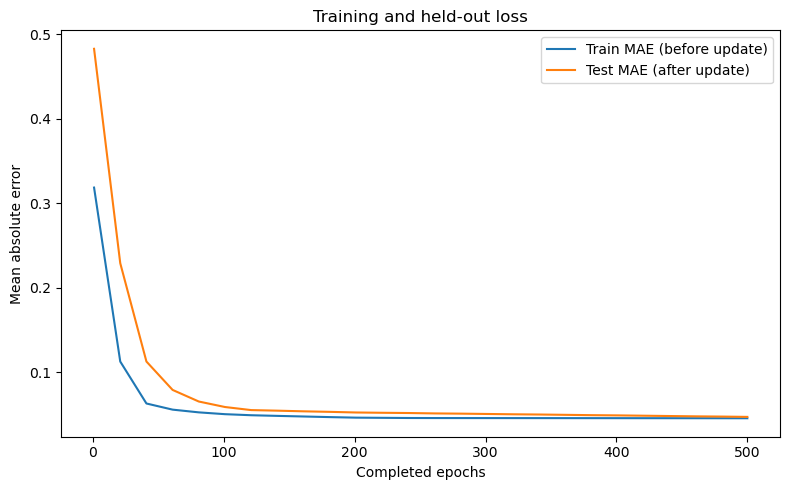

In [43]:
# Histories contain Python floats, so Matplotlib can plot them directly.
plt.figure(figsize=(8, 5))
plt.plot(epoch_count, train_loss_values, label="Train MAE (before update)")
plt.plot(epoch_count, test_loss_values, label="Test MAE (after update)")
plt.title("Training and held-out loss")
plt.ylabel("Mean absolute error")
plt.xlabel("Completed epochs")
plt.legend()
plt.tight_layout()
plt.show()


In [44]:
# The fitted values need not equal the truth exactly: data are noisy and finite,
# and the optimizer approximately minimizes the sample MAE objective.
print("Learned parameters:", model_0.state_dict())
print(f"Generating parameters: weight={weight}, bias={bias}")


Learned parameters: OrderedDict({'weights': tensor([0.6364]), 'bias': tensor([0.3388])})
Generating parameters: weight=0.7, bias=0.3


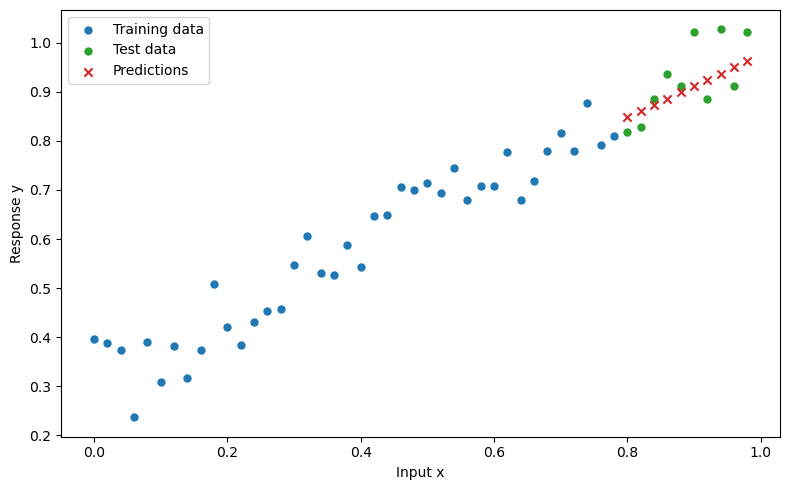

In [45]:
model_0.eval()
with torch.inference_mode():
    y_preds = model_0(X_test)  # Predict using the final trained parameters.

# Predictions describe the fitted line, not the random noise in each observation.
plot_predictions(train_data=X_train, train_labels=y_train,
                 test_data=X_test, test_labels=y_test, predictions=y_preds)


### 5. Save and reload a model

| Function | Role |
|---|---|
| `torch.save(model.state_dict(), path)` | Write parameter and persistent-buffer values to disk |
| `torch.load(path, ...)` | Read the saved dictionary |
| `model.load_state_dict(state)` | Copy values into a compatible model instance |

A `state_dict` does not contain the model's architecture or its optimizer state.
Recreate the same architecture before loading. To resume training with optimizer
history, also save `optimizer.state_dict()` and the epoch in a checkpoint.
The examples use `weights_only=True` for loading these tensor dictionaries and
`map_location="cpu"` so a checkpoint can be opened without its original GPU.


In [46]:
from pathlib import Path

# Relative paths are resolved from the notebook kernel's working directory.
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)  # Create it if missing.
MODEL_SAVE_PATH = MODEL_PATH / "01_pytorch_workflow_model.pth"

# Save values, not the full Python model object. Rerunning overwrites this checkpoint.
torch.save(model_0.state_dict(), MODEL_SAVE_PATH)
print("Saved model to:", MODEL_SAVE_PATH)


Saved model to: models/01_pytorch_workflow_model.pth


In [47]:
# Recreate the same architecture; these initial random values will be replaced.
loaded_model_0 = LinearRegressionModel()

# map_location controls where tensors from the saved file are read.
state = torch.load(MODEL_SAVE_PATH, map_location="cpu", weights_only=True)
loaded_model_0.load_state_dict(state)  # Pass the dictionary, not the file path.


<All keys matched successfully>

In [48]:
loaded_model_0.eval()  # Loading values does not automatically select evaluation mode.
with torch.inference_mode():
    loaded_model_preds = loaded_model_0(X_test)

# Verify that saving and loading preserves predictions; allclose allows tiny roundoff.
print("Predictions match:", torch.allclose(y_preds, loaded_model_preds))


Predictions match: True


---

### 6. Put it all together with `nn.Linear` and an available device

The same workflow now uses a built-in layer. Both the model and the data must
be on the selected device. CUDA or MPS can accelerate larger workloads; this
tiny example also runs on the CPU. This section reuses `plot_predictions()` above.


In [49]:
# Select hardware that this PyTorch installation can actually use.
if torch.cuda.is_available():
    device = "cuda"  # CUDA GPU.
elif torch.backends.mps.is_available():
    device = "mps"   # Supported Apple GPU through Metal.
else:
    device = "cpu"   # Works without a GPU.

print("Selected device:", device)


Selected device: mps


#### 6.1 Data

This second simulation uses a different seed and noise SD of 0.02.
Its loss is therefore not directly comparable to the earlier SD-0.05 example.


Train: torch.Size([40, 1]) torch.Size([40, 1]) on mps:0
Test: torch.Size([10, 1]) torch.Size([10, 1]) on mps:0


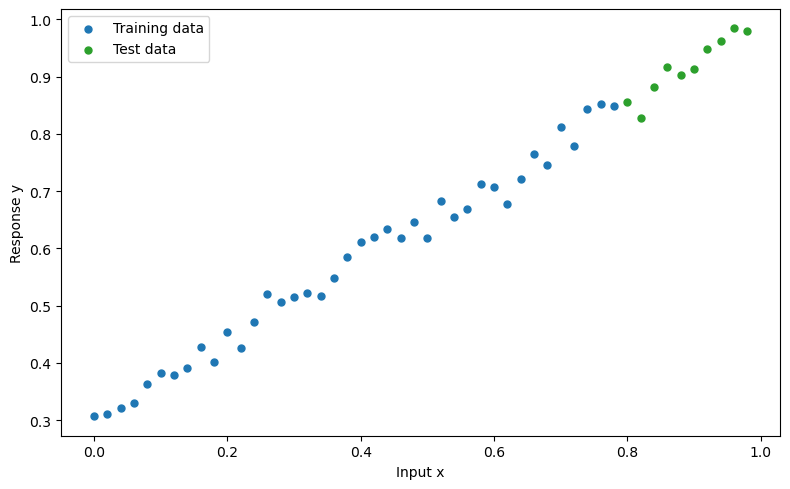

In [50]:
weight, bias = 0.7, 0.3
torch.manual_seed(123)
start, end, step = 0, 1, 0.02
X = torch.arange(start, end, step).unsqueeze(1)  # (50, 1), initially on CPU.
error = 0.02 * torch.randn(size=(len(X), 1))     # Independent noise, SD = 0.02.
y = bias + weight * X + error

# Use the same ordered 80/20 split, then move BOTH features and targets.
train_split = int(0.8 * len(X))
X_train = X[:train_split].to(device)
y_train = y[:train_split].to(device)
X_test = X[train_split:].to(device)
y_test = y[train_split:].to(device)

print("Train:", X_train.shape, y_train.shape, "on", X_train.device)
print("Test:", X_test.shape, y_test.shape, "on", X_test.device)

# The plotting helper detaches and transfers values to CPU internally.
plot_predictions(X_train, y_train, X_test, y_test)


#### 6.2 A linear model using `nn.Linear`

`nn.Linear(in_features=p, out_features=q)` computes

$$Y_{n\times q}=X_{n\times p}W_{q\times p}^{\mathsf T}
  +\mathbf 1_n b_q^{\mathsf T}.$$

Its weight tensor is `(q, p)` and its bias is `(q,)`. Here, `p=q=1`, so it
represents the same slope/intercept model as before. Inputs and outputs both
have shape `(n, 1)`. `nn.Linear` does not include an activation function.


In [51]:
class LinearRegressionModelV2(nn.Module):
    def __init__(self):
        super().__init__()

        # Creates randomly initialized weight (1, 1) and bias (1,), with gradients.
        # Assigning this layer registers it as a child module, so its parameters
        # are included automatically in model.parameters() and model.state_dict().
        self.linear_layer = nn.Linear(in_features=1, out_features=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.linear_layer(x)  # x @ weight.T + bias.

torch.manual_seed(123)
model_1 = LinearRegressionModelV2()

# parameters() is an iterator; next() gets its first parameter tensor.
print("Initial model device:", next(model_1.parameters()).device)


Initial model device: cpu


In [52]:
# Move registered parameters and buffers BEFORE creating the optimizer.
# Module.to() changes the model itself and also returns it.
model_1.to(device)
print("Model device:", next(model_1.parameters()).device)


Model device: mps:0


#### 6.3 Training

In [53]:
loss_fn = nn.L1Loss()  # Same MAE objective as in the first example.

# A NEW model needs an optimizer linked to that model's parameters.
# Reusing the earlier optimizer would leave it linked to model_0 instead.
optimizer = torch.optim.SGD(params=model_1.parameters(), lr=0.01)


In [54]:
# Full-batch training: one pass over the training data and one update per epoch.
epochs = 1000
train_loss_values, test_loss_values, epoch_count = [], [], []

for epoch in range(epochs):
    # 0. Select training behavior. This alone does not calculate gradients.
    model_1.train()

    # 1. Predict with current parameters: (40, 1) -> (40, 1).
    y_pred = model_1(X_train)

    # 2. Compute a scalar MAE. Predictions and targets must have matching shapes.
    loss = loss_fn(y_pred, y_train)

    # 3. Clear gradients from the previous step; backward() otherwise accumulates them.
    optimizer.zero_grad()

    # 4. Compute d(loss)/d(parameter) and store it in each parameter's .grad.
    loss.backward()

    # 5. Update this model's parameters using the gradients and learning rate.
    optimizer.step()

    # Evaluate THIS model after the update, without building a gradient graph.
    model_1.eval()
    with torch.inference_mode():
        test_pred = model_1(X_test)
        test_loss = loss_fn(test_pred, y_test)

    # Log occasionally. item() gives a plain float on CPU, CUDA, or MPS.
    # Store numbers, not graph-attached tensors, in the history lists.
    if epoch % 50 == 0 or epoch == epochs - 1:
        epoch_count.append(epoch + 1)  # Display completed epochs, starting at 1.
        train_loss_values.append(loss.item())
        test_loss_values.append(test_loss.item())
        print(f"Epoch {epoch + 1:4d} | Train MAE {loss.item():.4f} "
              f"| Test MAE {test_loss.item():.4f}")

# Train loss above is measured BEFORE each update; test loss is measured AFTER it.
# Rerunning this cell continues from the current fitted parameters.
# To restart from scratch, rerun model initialization AND optimizer creation first.


Epoch    1 | Train MAE 0.6985 | Test MAE 1.2339
Epoch   51 | Train MAE 0.2312 | Test MAE 0.6316
Epoch  101 | Train MAE 0.1558 | Test MAE 0.3994
Epoch  151 | Train MAE 0.1335 | Test MAE 0.2963
Epoch  201 | Train MAE 0.1165 | Test MAE 0.2508
Epoch  251 | Train MAE 0.1003 | Test MAE 0.2156
Epoch  301 | Train MAE 0.0841 | Test MAE 0.1810
Epoch  351 | Train MAE 0.0680 | Test MAE 0.1458
Epoch  401 | Train MAE 0.0530 | Test MAE 0.1122
Epoch  451 | Train MAE 0.0395 | Test MAE 0.0806
Epoch  501 | Train MAE 0.0276 | Test MAE 0.0580
Epoch  551 | Train MAE 0.0200 | Test MAE 0.0326
Epoch  601 | Train MAE 0.0178 | Test MAE 0.0205
Epoch  651 | Train MAE 0.0170 | Test MAE 0.0131
Epoch  701 | Train MAE 0.0167 | Test MAE 0.0131
Epoch  751 | Train MAE 0.0166 | Test MAE 0.0131
Epoch  801 | Train MAE 0.0166 | Test MAE 0.0132
Epoch  851 | Train MAE 0.0166 | Test MAE 0.0133
Epoch  901 | Train MAE 0.0166 | Test MAE 0.0132
Epoch  951 | Train MAE 0.0166 | Test MAE 0.0130
Epoch 1000 | Train MAE 0.0166 | Test MAE

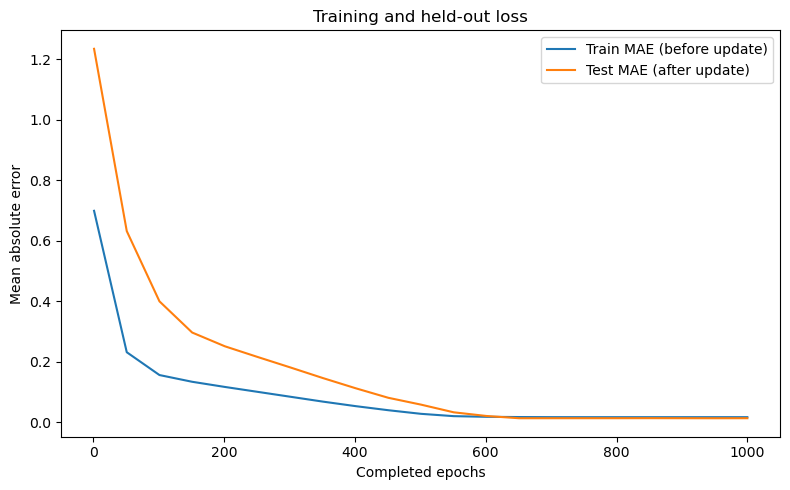

In [55]:
# Histories contain Python floats, so Matplotlib can plot them directly.
plt.figure(figsize=(8, 5))
plt.plot(epoch_count, train_loss_values, label="Train MAE (before update)")
plt.plot(epoch_count, test_loss_values, label="Test MAE (after update)")
plt.title("Training and held-out loss")
plt.ylabel("Mean absolute error")
plt.xlabel("Completed epochs")
plt.legend()
plt.tight_layout()
plt.show()


#### 6.4 Make predictions

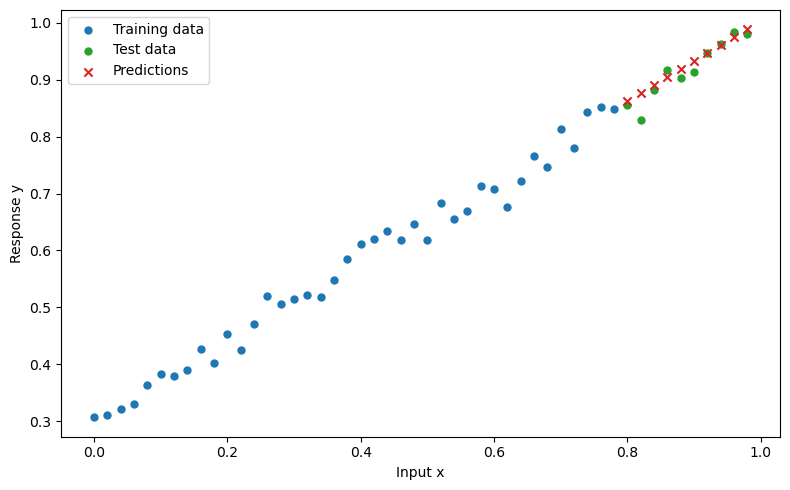

In [56]:
model_1.eval()
with torch.inference_mode():
    y_preds = model_1(X_test)  # Model and X_test are already on the same device.

# Only the plotting conversion moves values to CPU; the model stays on its device.
plot_predictions(X_train, y_train, X_test, y_test, predictions=y_preds)


#### 6.5 Saving and loading a model

In [57]:
from pathlib import Path

MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)
MODEL_SAVE_PATH = MODEL_PATH / "01_pytorch_workflow_model_1.pth"

# State values may be stored on a GPU; map_location below handles loading on CPU.
torch.save(model_1.state_dict(), MODEL_SAVE_PATH)
print("Saved model to:", MODEL_SAVE_PATH)


Saved model to: models/01_pytorch_workflow_model_1.pth


In [58]:
# Recreate the same architecture on CPU, then restore its saved values.
loaded_model_1 = LinearRegressionModelV2()
state = torch.load(MODEL_SAVE_PATH, map_location="cpu", weights_only=True)
loaded_model_1.load_state_dict(state)

# X_test is on device, so move the restored model there before prediction.
loaded_model_1.to(device)
loaded_model_1.eval()
with torch.inference_mode():
    loaded_model_1_preds = loaded_model_1(X_test)

print("Predictions match:", torch.allclose(y_preds, loaded_model_1_preds))


Predictions match: True


## Quick reference: what does each command change?

| Command | Main effect |
|---|---|
| `model.train()` / `model.eval()` | Selects training / evaluation behavior; does not itself enable or disable gradients |
| `with torch.inference_mode():` | Disables autograd recording for prediction; does not call `eval()` |
| `loss.backward()` | Computes gradients; does not update weights |
| `optimizer.zero_grad()` | Clears accumulated parameter gradients |
| `optimizer.step()` | Updates parameters using their gradients |
| `loss.item()` | Extracts a Python number for logging; do not use it as the loss for `backward()` |
| `tensor.detach()` | Returns a tensor detached from autograd; it shares storage |
| `model.to(device)` | Moves registered model parameters and buffers |
| `tensor = tensor.to(device)` | Keeps the tensor returned on the requested device |

**When debugging:** inspect `X.shape`, `y.shape`, `X.dtype`, `X.device`, and
`next(model.parameters()).device`. For this regression, predictions and targets
must both be `(n, 1)`. Check that the optimizer belongs to the model being trained.

**Official references:** [Autograd and evaluation modes](https://docs.pytorch.org/docs/stable/notes/autograd.html),
[Linear layers](https://docs.pytorch.org/docs/stable/generated/torch.nn.Linear.html),
and [saving/loading models](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html).
